<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       Model        MAE       RMSE      MAPE  Training Time
0  SimpleRNN   9.206052  11.729219  3.851820       4.591453
1       LSTM  24.056434  29.559740  9.710202       2.132986


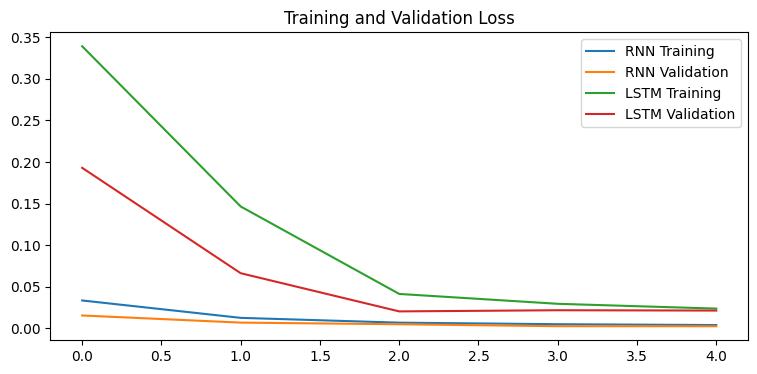

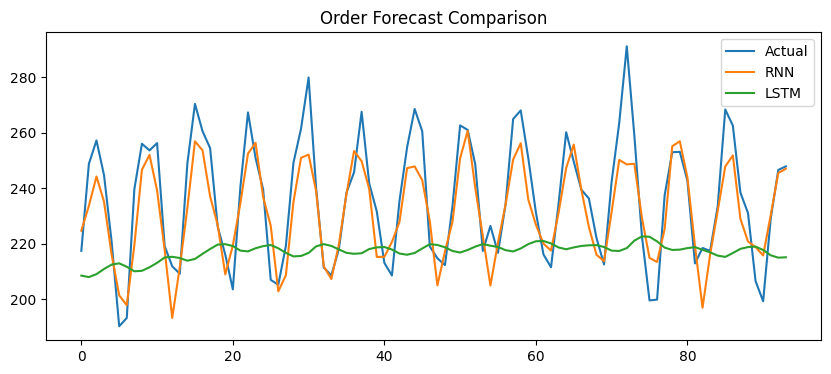

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate daily order data
np.random.seed(42)
days = np.arange(500)

orders = 200 + 30*np.sin(2*np.pi*days/7) \
         + 40*np.sin(2*np.pi*days/365) \
         + np.random.normal(0, 8, 500)

scaler = MinMaxScaler()
data = scaler.fit_transform(orders.reshape(-1, 1))

# Create sequences
X, y = [], []
for i in range(len(data)-30):
    X.append(data[i:i+30])
    y.append(data[i+30])

X, y = np.array(X), np.array(y)

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

def train_model(kind):
    layer = (tf.keras.layers.SimpleRNN(32) if kind == 'RNN'
             else tf.keras.layers.LSTM(32))

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(30, 1)),
        layer,
        tf.keras.layers.Dense(1)
    ])

    model.compile(optimizer='adam', loss='mse')

    start = time.time()
    history = model.fit(
        X_train, y_train, epochs=5,
        batch_size=32, validation_split=0.2, verbose=0
    )
    elapsed = time.time() - start

    pred = model.predict(X_test, verbose=0)
    actual = scaler.inverse_transform(y_test)
    predicted = scaler.inverse_transform(pred)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual-predicted)/(actual+1e-8)))*100

    return model, history, elapsed, actual, predicted, mae, rmse, mape

rnn = train_model('RNN')
lstm = train_model('LSTM')

# Results table
df = pd.DataFrame([
    ['SimpleRNN', rnn[5], rnn[6], rnn[7], rnn[2]],
    ['LSTM', lstm[5], lstm[6], lstm[7], lstm[2]]
], columns=['Model', 'MAE', 'RMSE', 'MAPE', 'Training Time'])

print(df)

# Loss curves
plt.figure(figsize=(9, 4))
plt.plot(rnn[1].history['loss'], label='RNN Training')
plt.plot(rnn[1].history['val_loss'], label='RNN Validation')
plt.plot(lstm[1].history['loss'], label='LSTM Training')
plt.plot(lstm[1].history['val_loss'], label='LSTM Validation')
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

# Forecast comparison
plt.figure(figsize=(10, 4))
plt.plot(rnn[3], label='Actual')
plt.plot(rnn[4], label='RNN')
plt.plot(lstm[4], label='LSTM')
plt.title("Order Forecast Comparison")
plt.legend()
plt.show()